In [ ]:
#  install the library
!pip install segmentation-models-pytorch albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

In [ ]:
import os
!pip install unrar
!unrar x /content/Datasets.rar

print("Contents of the main 'Datasets' directory after 2extraction:")
!ls -R /content/Datasets

Streaming output truncated to the last 5000 lines.
Extracting  Datasets/test/malignant/489_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/491_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/494_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/496_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/499_2HC_Annotation.png                77%  OK 
Extracting  Datasets/test/malignant/49_2HC.png                            77%  OK 
Extracting  Datasets/test/malignant/501_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/503_HC_Annotation.png                 77%  OK 
Extracting  Datasets/test/malignant/504_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/507_HC.png                            77%  OK 
Extracting  Datasets/test/mal

In [ ]:
!ls -R /content/Datasets/Datasets/

/content/Datasets/Datasets/:
benign	malignant  normal

/content/Datasets/Datasets/benign:
 100_HC.png    18_HC.png     277_HC.png    63_HC.png
 101_HC.png    190_HC.png    278_2HC.png   64_2HC.png
 102_2HC.png   191_4HC.png   279_HC.png    65_2HC.png
 10_2HC.png    192_2HC.png   280_HC.png    66_HC.png
 103_HC.png    193_HC.png    281_HC.png    67_HC.png
 104_HC.png    194_2HC.png   282_2HC.png   68_HC.png
 105_3HC.png   195_HC.png    283_HC.png    69_HC.png
 106_HC.png    196_HC.png    284_HC.png    6_HC.png
 107_3HC.png   197_HC.png    285_HC.png    70_2HC.png
 108_HC.png    198_HC.png    286_HC.png    71_HC.png
 109_HC.png    199_HC.png    287_4HC.png   72_HC.png
 110_HC.png    19_HC.png     288_HC.png    7_2HC.png
 111_HC.png    1_HC.png      289_HC.png    73_2HC.png
 112_2HC.png   200_HC.png    28_HC.png	   74_2HC.png
 113_HC.png    201_HC.png    290_HC.png    75_HC.png
 114_HC.png    202_2HC.png   291_HC.png    76_HC.png
 115_HC.png    203_HC.png    292_2HC.png   77_HC.png
 116_H

In [ ]:
import os

DATA_ROOT = "/content/Datasets/Datasets" # Corrected root based on ls -R output

all_files = []
for root, _, files in os.walk(DATA_ROOT):
    for file in files:
        if file.endswith(".png"):
            all_files.append(os.path.join(root, file))

image_candidates = {} # Dictionary to store image paths keyed by their base name
mask_candidates = {}  # Dictionary to store mask paths keyed by their base name

for file_path in all_files:
    # Check for mask patterns
    if file_path.endswith("_Annotation.png"):
        base_name = file_path.replace("_Annotation.png", "")
        mask_candidates[base_name] = file_path
    elif file_path.endswith("_mask.png"):
        base_name = file_path.replace("_mask.png", "")
        mask_candidates[base_name] = file_path
    # Assume anything else ending with .png is an image
    elif file_path.endswith(".png"):
        base_name = file_path.replace(".png", "")
        image_candidates[base_name] = file_path

# Find common keys (base names) that have both an image and a mask
common_keys = set(image_candidates.keys()) & set(mask_candidates.keys())

# Build the final lists of paired images and masks
images = [image_candidates[key] for key in common_keys]
masks = [mask_candidates[key] for key in common_keys]

print(f"Total Paired Images Found: {len(images)}")
print(f"Total Paired Masks Found: {len(masks)}")
assert len(images) == len(masks), "Error: Mismatch in paired image and mask count after filtering!"

# Optional: Verify if there are any unmatched files (good for debugging)
unmatched_images = set(image_candidates.keys()) - common_keys
unmatched_masks = set(mask_candidates.keys()) - common_keys

if unmatched_images:
    print(f"Warning: {len(unmatched_images)} images found without a corresponding mask.")
if unmatched_masks:
    print(f"Warning: {len(unmatched_masks)} masks found without a corresponding image.")

Total Paired Images Found: 999
Total Paired Masks Found: 999


In [ ]:
import cv2
import torch
from torch.utils.data import Dataset
import numpy as np

class UltrasoundDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

        assert len(self.image_paths) == len(self.mask_paths), "Image and mask path lists must have the same length."

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):#reads the image in memory via opencv dynamically
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        # Load as grayscale (1 channel) for typical ultrasound scans
        image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Handle potential errors during image loading
        if image is None:
            raise FileNotFoundError(f"Image not found or unable to load: {img_path}")
        if mask is None:
            raise FileNotFoundError(f"Mask not found or unable to load: {mask_path}")

        # Normalize mask to binary values (0 and 1)
        # Ensure mask is float32 for PyTorch operations later
        mask = np.where(mask > 127, 1.0, 0.0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # Ensure image has a channel dimension: [1, H, W] if not already handled by ToTensorV2
        if len(image.shape) == 2:
            image = image.unsqueeze(0) if torch.is_tensor(image) else np.expand_dims(image, axis=0)
        # Ensure mask has a channel dimension: [1, H, W] if not already handled by ToTensorV2
        if len(mask.shape) == 2:
            mask = mask.unsqueeze(0) if torch.is_tensor(mask) else np.expand_dims(mask, axis=0)

        return image, mask

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Define transformations
IMG_HEIGHT = 256
IMG_WIDTH = 256

transform = A.Compose([
    A.Resize(height=IMG_HEIGHT, width=IMG_WIDTH),
    A.Normalize(mean=(0.5,), std=(0.5,), max_pixel_value=255.0), # For grayscale images
    ToTensorV2(), # Converts to PyTorch tensor and adds channel dimension (C, H, W)
])

# Split image and mask paths while maintaining correspondence
# 'images' and 'masks' lists are available from previous cell execution, and they contain full paths.
# We split both lists in parallel to ensure correct image-mask pairing.
train_images, val_images, train_masks, val_masks = train_test_split(
    images, masks, test_size=0.2, random_state=42
)

# Instantiate Datasets with the full image and mask paths
train_dataset = UltrasoundDataset(train_images, train_masks, transform=transform)
val_dataset = UltrasoundDataset(val_images, val_masks, transform=transform)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

print(f"Batches in Train Loader: {len(train_loader)}")
print(f"Batches in Val Loader: {len(val_loader)}")

Batches in Train Loader: 100
Batches in Val Loader: 25


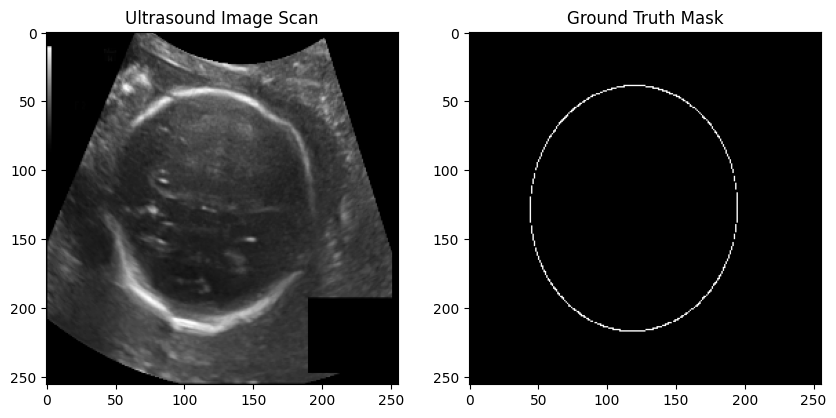

In [ ]:
import matplotlib.pyplot as plt

# Grab one batch
samples, targets = next(iter(train_loader))

# Plot the first item in the batch
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Ultrasound Image Scan")
plt.imshow(samples[0].squeeze(), cmap='gray')

plt.subplot(1, 2, 2)
plt.title("Ground Truth Mask")
plt.imshow(targets[0].squeeze(), cmap='gray')
plt.show()

In [ ]:
import torch.optim as optim
import segmentation_models_pytorch as smp # Ensure smp is imported if not already
import torch # Ensure torch is imported
import torch.nn as nn # Import torch.nn for BCEWithLogitsLoss

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Instantiate the U-Net model from segmentation_models_pytorch
# Using a pre-trained encoder for better performance
model = smp.Unet(
    encoder_name="resnext50_32x4d",
    encoder_weights="imagenet",         # Use pre-trained weights for the encoder
    in_channels=1,                      # Grayscale input images
    classes=1,                          # Binary segmentation output (mask)
    activation=None,                    # No activation here, will be applied in loss if needed
).to(device)

# Instantiate Loss and Optimizer
# A common and effective combination for segmentation is DiceLoss and BCEWithLogitsLoss

class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.5, bce_weight=0.5):
        super().__init__()
        self.dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)
        self.bce_loss = nn.BCEWithLogitsLoss()
        self.dice_weight = dice_weight
        self.bce_weight = bce_weight

    def forward(self, pred, target):
        dice = self.dice_loss(pred, target)
        bce = self.bce_loss(pred, target)
        return self.dice_weight * dice + self.bce_weight * bce

criterion = CombinedLoss() # Instantiate the combined loss
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)

# Learning rate scheduler - lowers LR if validation loss plateaus
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

print("Model, Loss, Optimizer, and Scheduler initialized.")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/100M [00:00<?, ?B/s]

Model, Loss, Optimizer, and Scheduler initialized.


In [ ]:
def dice_coefficient(preds, targets, smooth=1e-6):
    """Calculates the Dice Coefficient for a batch of binary predictions."""
    # Apply sigmoid and threshold at 0.5 to get binary mask
    preds = (torch.sigmoid(preds) > 0.5).float()

    preds = preds.view(-1)
    targets = targets.view(-1)

    intersection = (preds * targets).sum()
    return (2. * intersection + smooth) / (preds.sum() + targets.sum() + smooth)

In [ ]:
import time

EPOCHS = 20  # to see how it performs
best_val_loss = float('inf')

for epoch in range(EPOCHS):
    start_time = time.time()

    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    train_dice = 0.0

    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_dice += dice_coefficient(outputs, masks).item() * images.size(0)

    epoch_train_loss = train_loss / len(train_loader.dataset)
    epoch_train_dice = train_dice / len(train_loader.dataset)

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    val_dice = 0.0

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)

            val_loss += loss.item() * images.size(0)
            val_dice += dice_coefficient(outputs, masks).item() * images.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_dice = val_dice / len(val_loader.dataset)

    # Step the scheduler based on validation loss
    scheduler.step(epoch_val_loss)

    elapsed_time = time.time() - start_time

    # Print progress
    print(f"Epoch [{epoch+1}/{EPOCHS}] | Time: {elapsed_time:.1f}s")
    print(f"  Train Loss: {epoch_train_loss:.4f} | Train Dice: {epoch_train_dice:.4f}")
    print(f"  Val Loss:   {epoch_val_loss:.4f} | Val Dice:   {epoch_val_dice:.4f}")

    # Save best model checkpoints
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), 'best_unet_model.pth')
        print(" Saved new best model weights!")
    print("-" * 50)

Epoch [1/20] | Time: 27.2s
  Train Loss: 0.7956 | Train Dice: 0.0286
  Val Loss:   0.7114 | Val Dice:   0.0574
 Saved new best model weights!
--------------------------------------------------
Epoch [2/20] | Time: 24.4s
  Train Loss: 0.6834 | Train Dice: 0.0682
  Val Loss:   0.6525 | Val Dice:   0.0757
 Saved new best model weights!
--------------------------------------------------
Epoch [3/20] | Time: 25.0s
  Train Loss: 0.6259 | Train Dice: 0.0950
  Val Loss:   0.5984 | Val Dice:   0.1053
 Saved new best model weights!
--------------------------------------------------
Epoch [4/20] | Time: 25.4s
  Train Loss: 0.5795 | Train Dice: 0.1720
  Val Loss:   0.5625 | Val Dice:   0.1991
 Saved new best model weights!
--------------------------------------------------
Epoch [5/20] | Time: 26.0s
  Train Loss: 0.5492 | Train Dice: 0.2327
  Val Loss:   0.5386 | Val Dice:   0.2315
 Saved new best model weights!
--------------------------------------------------
Epoch [6/20] | Time: 25.8s
  Train 

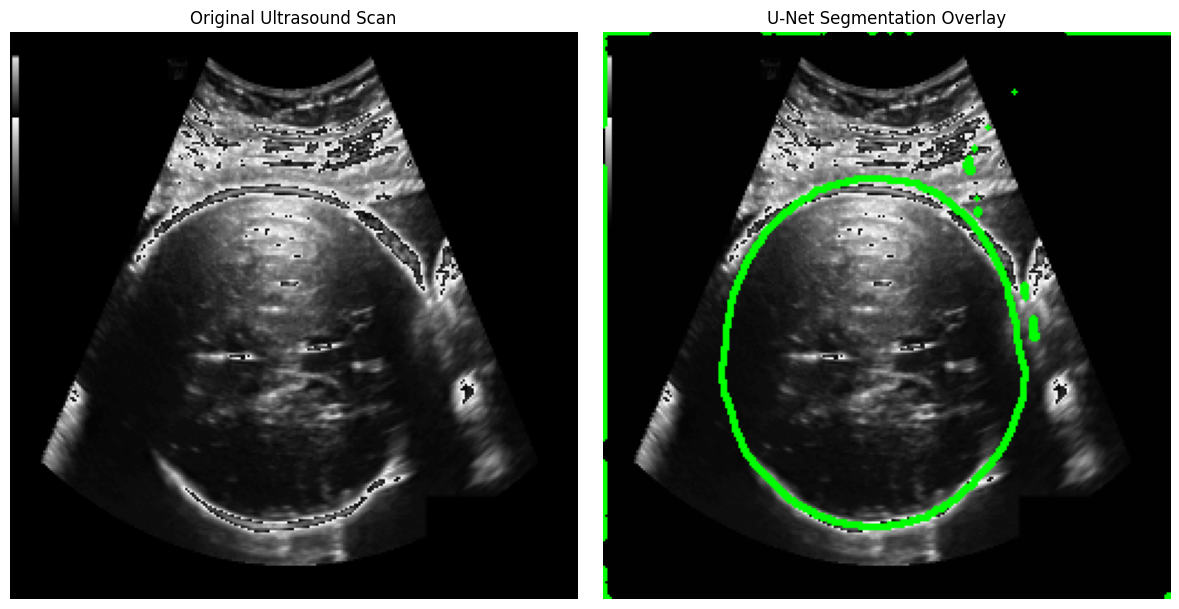

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Ensure model is in evaluation mode
model.eval()

# 2. Grab the first validation image and mask from your batch
# (Assuming val_images is the batch tensor from your previous step)
original_img_tensor = val_images[0].squeeze() # Shape: [H, W]
pred_tensor = predictions[0].squeeze()        # Shape: [H, W]

# 3. Convert the original tensor back to a standard 8-bit grayscale image
# Undo any normalization if you applied it (e.g., if you normalized by * 0.5 + 0.5)
# If you used standard normalization, adjust the scaling below accordingly:
img_grayscale = (original_img_tensor.numpy() * 255).astype(np.uint8)

# 4. Convert the grayscale image to 3-channel BGR/RGB so we can draw color on it
color_overlay = cv2.cvtColor(img_grayscale, cv2.COLOR_GRAY2RGB)

# 5. Convert prediction tensor to a binary mask (0 or 255)
pred_mask = (pred_tensor.numpy() * 255).astype(np.uint8)

# 6. Find contours from your U-Net prediction
contours, _ = cv2.findContours(pred_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 7. Draw the contours directly onto the original image
# Arguments: (target_image, contours_list, contour_idx (-1 means all), color (R,G,B), thickness)
cv2.drawContours(color_overlay, contours, -1, (0, 255, 0), thickness=2) # Bright Green Line

# 8. Plot the results side-by-side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Original Ultrasound Scan")
plt.imshow(img_grayscale, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("U-Net Segmentation Overlay")
plt.imshow(color_overlay)
plt.axis('off')

plt.tight_layout()
plt.show()

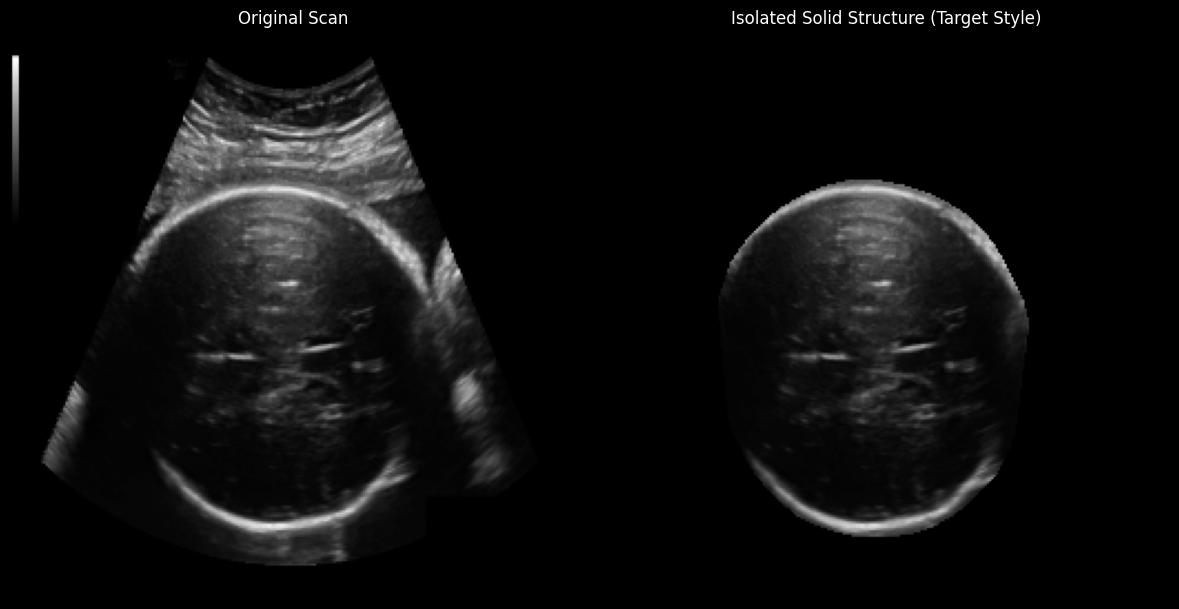

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Tensors & Un-normalization (Keep this clean)
original_img_tensor = val_images[0].squeeze().cpu()
pred_tensor = predictions[0].squeeze().cpu()

img_unnormalized = (original_img_tensor.numpy() * 0.5) + 0.5
img_unnormalized = np.clip(img_unnormalized, 0.0, 1.0)

# 2. Get the binary mask thresholded at 0.5
pred_mask_8bit = ((pred_tensor.numpy() > 0.5) * 255).astype(np.uint8)

# 3. FIX THE GAP: Find contours and use a Convex Hull to force it closed
contours, _ = cv2.findContours(pred_mask_8bit, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
solid_mask = np.zeros_like(pred_mask_8bit)

if len(contours) > 0:
    # Merge all contour fragments together to handle the gap on the right
    all_points = np.vstack(contours)

    # Create a convex hull (wraps a tight, closed elastic band around all points)
    hull = cv2.convexHull(all_points)

    # Fill the entire area inside the hull
    cv2.drawContours(solid_mask, [hull], -1, 255, thickness=cv2.FILLED)
else:
    # Fallback: if contours fail, use morphology to bridge gaps
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    solid_mask = cv2.morphologyEx(pred_mask_8bit, cv2.MORPH_CLOSE, kernel)
    # Fill any remaining holes inside
    contours_fallback, _ = cv2.findContours(solid_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(solid_mask, contours_fallback, -1, 255, thickness=cv2.FILLED)

# Convert solid mask to a float mask [0.0, 1.0]
binary_mask_float = (solid_mask / 255.0).astype(np.float32)

# 4. Multiply to isolate the full region
isolated_structure = img_unnormalized * binary_mask_float

# 5. Display the true solid result
plt.figure(figsize=(12, 6), facecolor='black')

plt.subplot(1, 2, 1)
plt.title("Original Scan", color='white')
plt.imshow(img_unnormalized, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("Isolated Solid Structure (Target Style)", color='white')
plt.imshow(isolated_structure, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.tight_layout()
plt.show()

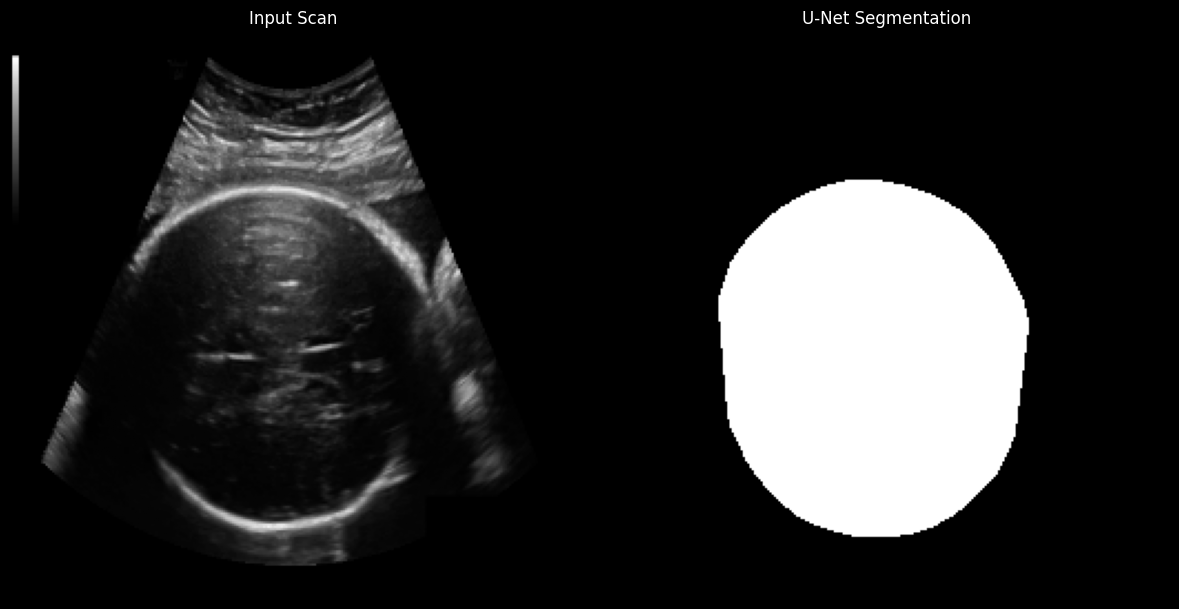

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# 1. Fetch raw tensors from the validation batch
original_img_tensor = val_images[0].squeeze().cpu()
pred_tensor = predictions[0].squeeze().cpu()

# 2. Get the clean 8-bit un-normalized original image for display
img_unnormalized = (original_img_tensor.numpy() * 0.5) + 0.5
img_unnormalized = np.clip(img_unnormalized, 0.0, 1.0)
img_8bit = (img_unnormalized * 255).astype(np.uint8)

# 3. Process prediction into a solid, filled binary mask (0 and 255)
pred_mask_8bit = ((pred_tensor.numpy() > 0.5) * 255).astype(np.uint8)
contours, _ = cv2.findContours(pred_mask_8bit, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

pure_binary_segmentation = np.zeros_like(pred_mask_8bit)
if len(contours) > 0:
    all_points = np.vstack(contours)
    hull = cv2.convexHull(all_points)
    # Fill the mask with pure white (255)
    cv2.drawContours(pure_binary_segmentation, [hull], -1, 255, thickness=cv2.FILLED)
else:
    # Fallback to standard morphology if contours are empty
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    pure_binary_segmentation = cv2.morphologyEx(pred_mask_8bit, cv2.MORPH_CLOSE, kernel)
    contours_fallback, _ = cv2.findContours(pure_binary_segmentation, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(pure_binary_segmentation, contours_fallback, -1, 255, thickness=cv2.FILLED)

# 4. Plot the exact layout matching your reference image
plt.figure(figsize=(12, 6), facecolor='black')

plt.subplot(1, 2, 1)
plt.title("Input Scan", color='white')
plt.imshow(img_8bit, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title("U-Net Segmentation", color='white')
# This renders a flat, solid white blob on a pure black background
plt.imshow(pure_binary_segmentation, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.tight_layout()
plt.show()

 Global Pixel Accuracy: 98.52%
 Area Under ROC Curve (AUC): 0.7858


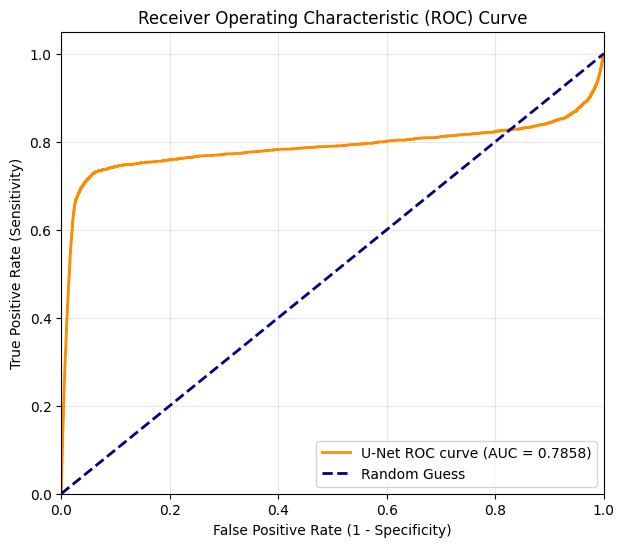

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score
import torch

# 1. Put model in evaluation mode
model.eval()

# 2. Grab a batch from your validation loader
val_images, val_masks = next(iter(val_loader))

# 3. Get raw probability predictions from the network
with torch.no_grad():
    outputs = model(val_images.to(device))
    probs = torch.sigmoid(outputs).cpu().numpy() # Raw continuous values [0.0, 1.0]

# 4. Flatten the ground truth masks and predicted probabilities for metric calculation
# We combine all pixels in the batch to get a global score
y_true = val_masks.numpy().flatten()
y_scores = probs.flatten()

# Convert predictions to hard binary labels (0 or 1) at a 0.5 threshold to calculate basic accuracy
y_pred_binary = (y_scores > 0.5).astype(int)

# 5. Compute Metrics
auc_score = roc_auc_score(y_true, y_scores)
pixel_accuracy = accuracy_score(y_true, y_pred_binary)

print(f" Global Pixel Accuracy: {pixel_accuracy * 100:.2f}%")
print(f" Area Under ROC Curve (AUC): {auc_score:.4f}")

# 6. Plot the ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_scores)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'U-Net ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

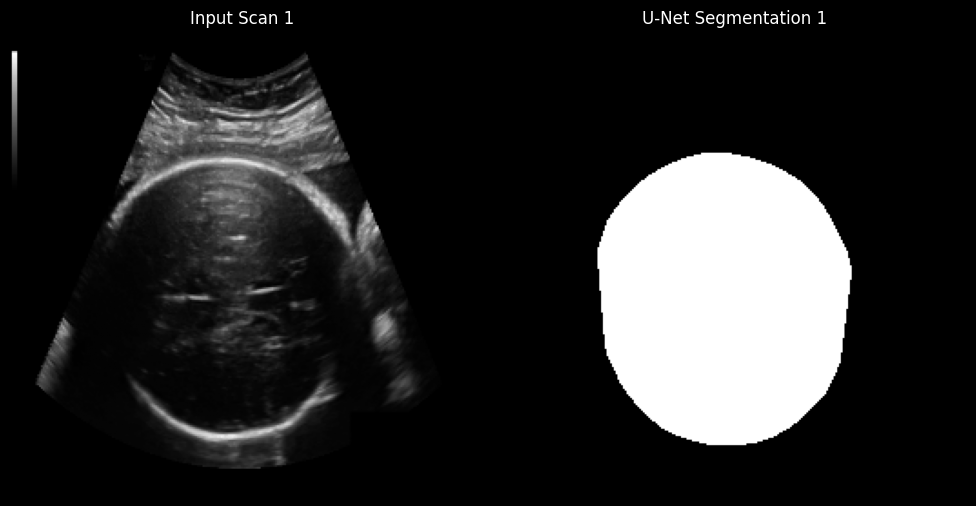

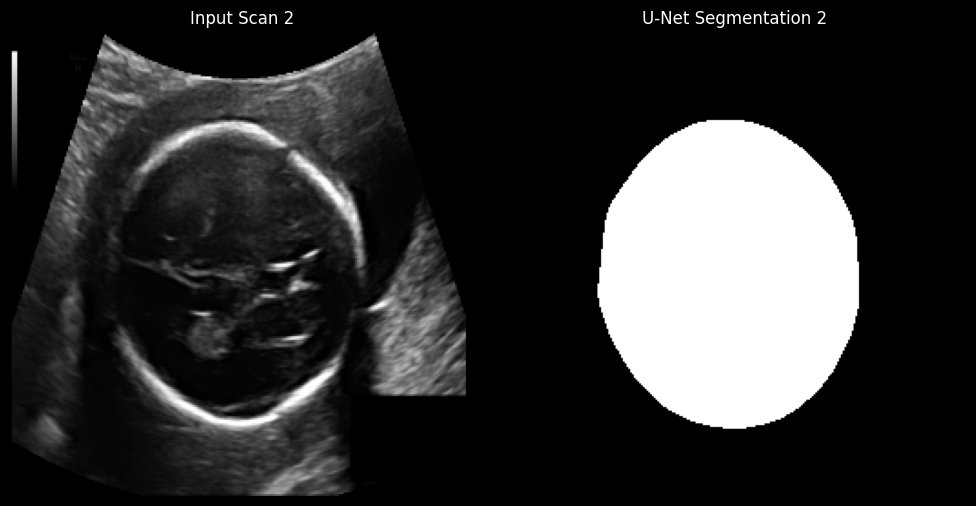

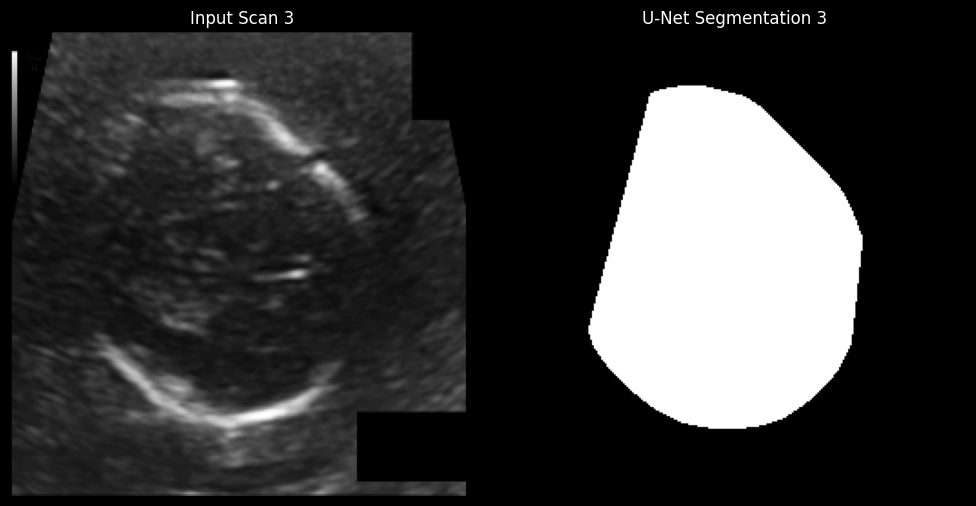

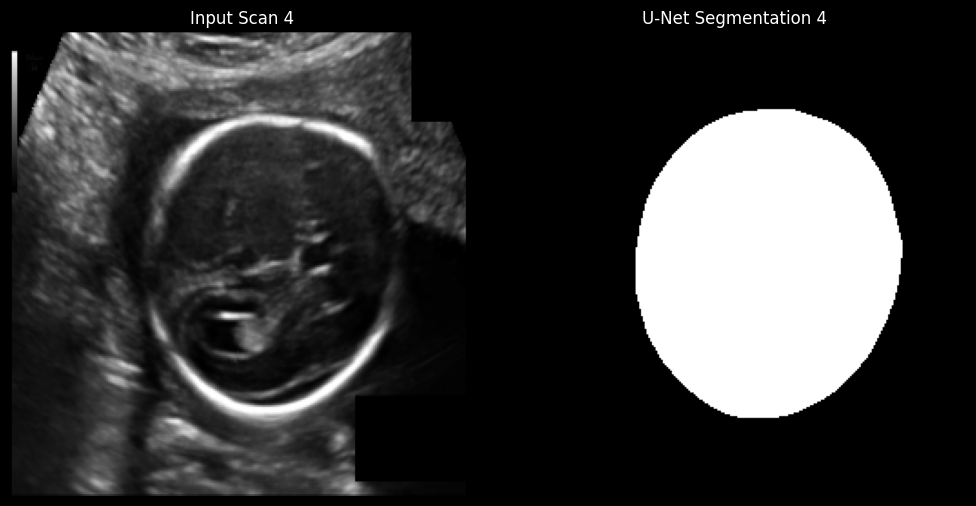

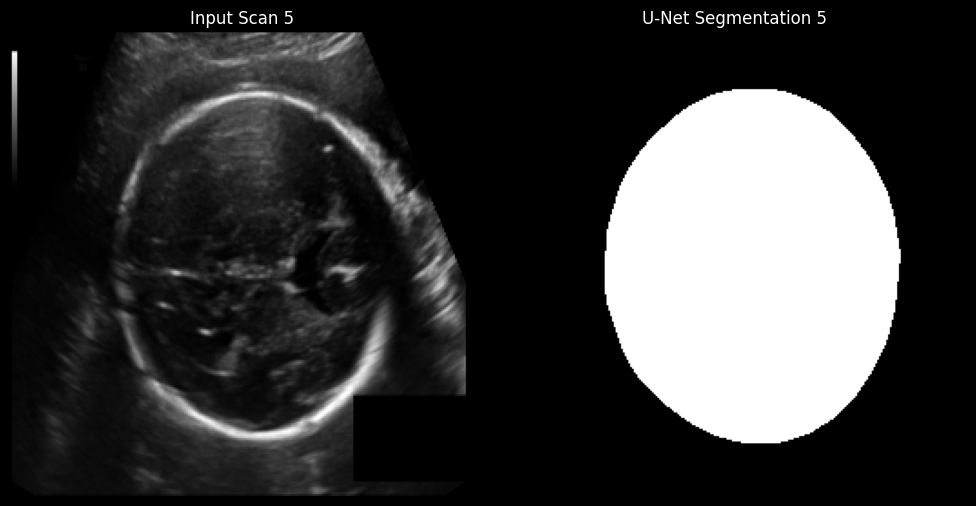

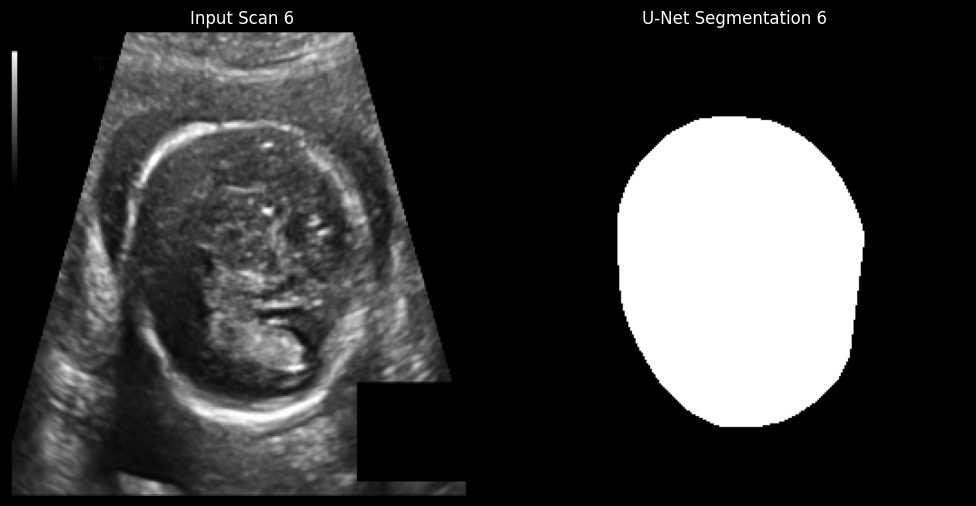

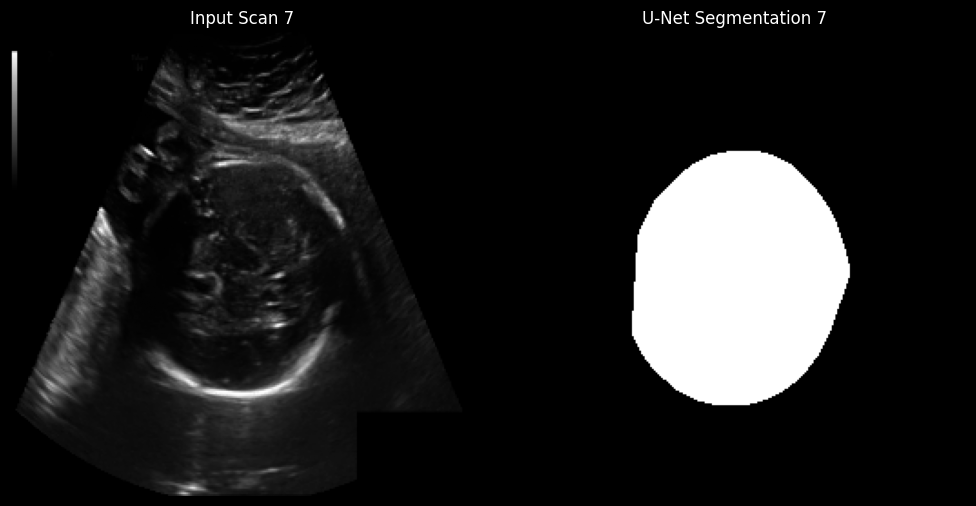

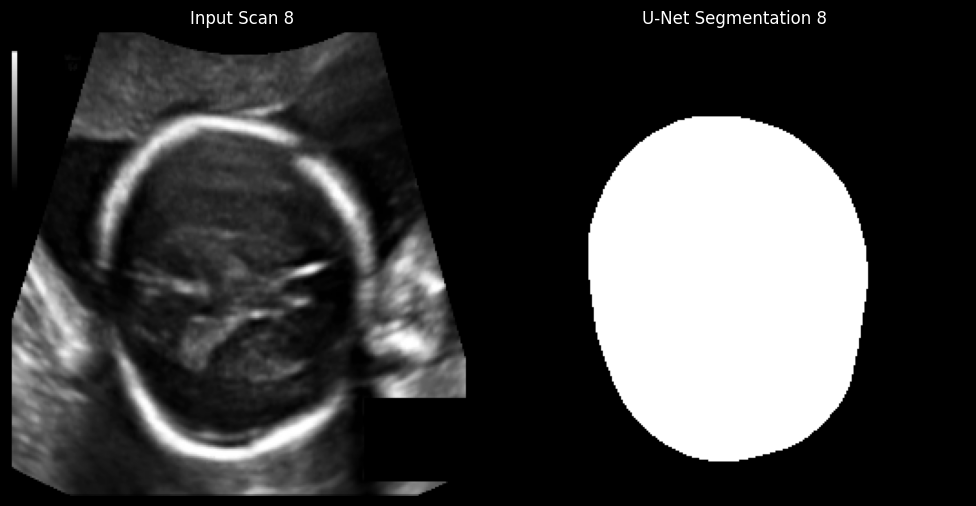

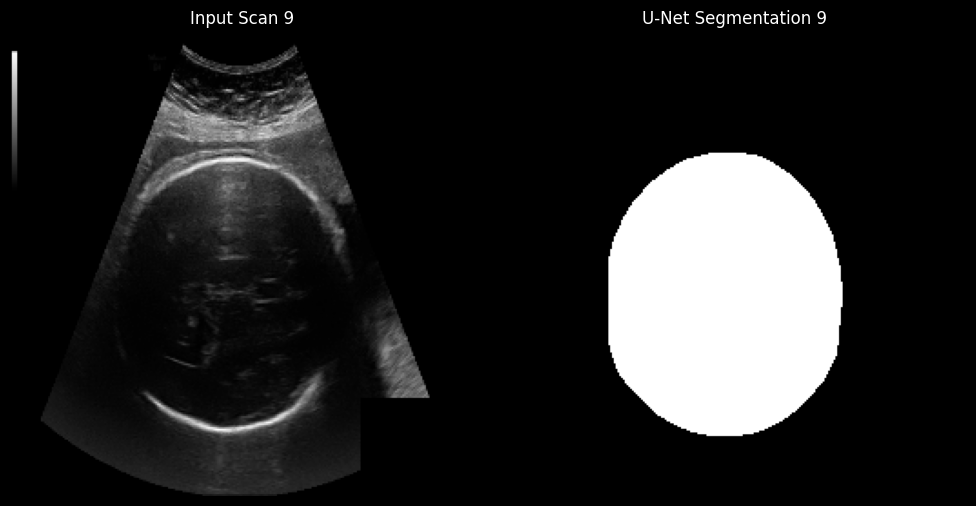

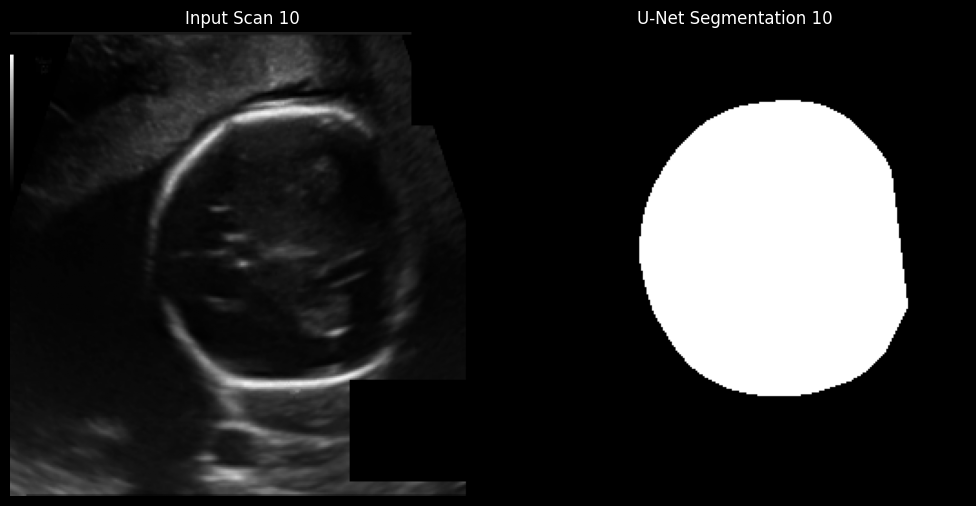

✅ Successfully processed 10 images! Files saved in: /unet_segmentation_results


In [ ]:
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

# 1. Create a directory to save your results inside Colab
output_dir = "unet_segmentation_results"
os.makedirs(output_dir, exist_ok=True)

# 2. Put model in evaluation mode
model.eval()

# 3. Counters for tracking
images_processed = 0
max_images = 10

# Disable gradient calculation for faster inference
with torch.no_grad():
    for batch_images, batch_masks in val_loader:
        if images_processed >= max_images:
            break

        # Move batch to the same device as the model (GPU)
        batch_images_gpu = batch_images.to(device)
        predictions = model(batch_images_gpu)
        predictions = torch.sigmoid(predictions).cpu() # Get probabilities back on CPU

        # Iterate through the images inside the current batch
        for i in range(len(batch_images)):
            if images_processed >= max_images:
                break

            # Extract individual tensors
            original_img_tensor = batch_images[i].squeeze()
            pred_tensor = predictions[i].squeeze()

            # --- POST-PROCESSING PIPELINE ---
            # Un-normalize the input scan
            img_unnormalized = (original_img_tensor.numpy() * 0.5) + 0.5
            img_unnormalized = np.clip(img_unnormalized, 0.0, 1.0)
            img_8bit = (img_unnormalized * 255).astype(np.uint8)

            # Create the solid binary mask via Convex Hull
            pred_mask_8bit = ((pred_tensor.numpy() > 0.5) * 255).astype(np.uint8)
            contours, _ = cv2.findContours(pred_mask_8bit, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

            pure_binary_segmentation = np.zeros_like(pred_mask_8bit)
            if len(contours) > 0:
                all_points = np.vstack(contours)
                hull = cv2.convexHull(all_points)
                cv2.drawContours(pure_binary_segmentation, [hull], -1, 255, thickness=cv2.FILLED)
            else:
                kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
                pure_binary_segmentation = cv2.morphologyEx(pred_mask_8bit, cv2.MORPH_CLOSE, kernel)

            # --- PLOTTING & VISUALIZATION ---
            fig, axes = plt.subplots(1, 2, figsize=(10, 5), facecolor='black')

            axes[0].imshow(img_8bit, cmap='gray')
            axes[0].set_title(f"Input Scan {images_processed + 1}", color='white')
            axes[0].axis('off')

            axes[1].imshow(pure_binary_segmentation, cmap='gray', vmin=0, vmax=255)
            axes[1].set_title(f"U-Net Segmentation {images_processed + 1}", color='white')
            axes[1].axis('off')

            plt.tight_layout()

            # Save the figure to your folder
            save_path = os.path.join(output_dir, f"result_{images_processed + 1}.png")
            plt.savefig(save_path, facecolor=fig.get_facecolor(), edgecolor='none')

            # Display it in the Colab notebook output
            plt.show()
            plt.close()

            images_processed += 1

print(f"✅ Successfully processed {images_processed} images! Files saved in: /{output_dir}")

Processing images for batch AUC calculation...

 Results across 10 Validation Images:
 Aggregate Pixel Accuracy: 98.50%
 Aggregate AUC-ROC Score:  0.7793


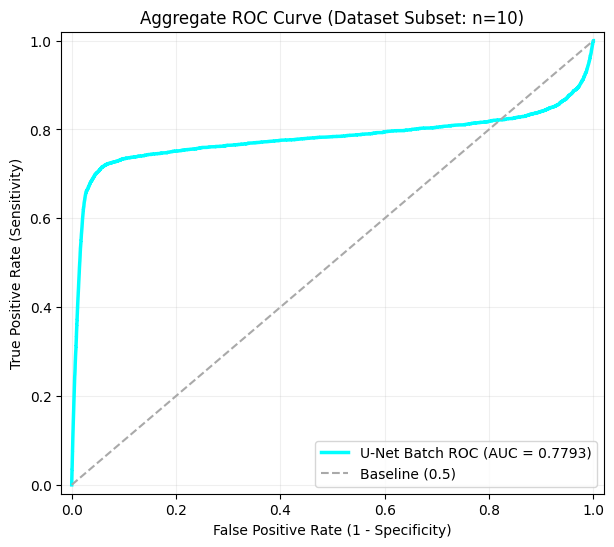

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

# 1. Initialize lists to aggregate pixels across images
all_y_true = []
all_y_scores = []

model.eval()
images_counted = 0
max_images = 10

print("Processing images for batch AUC calculation...")

with torch.no_grad():
    for batch_images, batch_masks in val_loader:
        if images_counted >= max_images:
            break

        # Send to GPU for fast execution
        batch_images_gpu = batch_images.to(device)
        outputs = model(batch_images_gpu)
        probs = torch.sigmoid(outputs).cpu().numpy() # Extract raw probabilities
        masks_np = batch_masks.numpy()

        # Process individual images out of the current batch
        for i in range(len(batch_images)):
            if images_counted >= max_images:
                break

            # Flatten pixels for this specific image scene
            all_y_true.append(masks_np[i].flatten())
            all_y_scores.append(probs[i].flatten())

            images_counted += 1

# 2. Concatenate all collected pixels into massive 1D arrays
y_true_global = np.concatenate(all_y_true)
y_scores_global = np.concatenate(all_y_scores)

# Create hard binary classifications at a 0.5 threshold for standard accuracy calculation
y_pred_binary_global = (y_scores_global > 0.5).astype(int)

# 3. Compute Metrics over the entire 10-image canvas
global_auc = roc_auc_score(y_true_global, y_scores_global)
global_pixel_acc = accuracy_score(y_true_global, y_pred_binary_global)

print("\n" + "="*40)
print(f" Results across {images_counted} Validation Images:")
print(f" Aggregate Pixel Accuracy: {global_pixel_acc * 100:.2f}%")
print(f" Aggregate AUC-ROC Score:  {global_auc:.4f}")
print("="*40)

# 4. Generate and Plot the Final Aggregate ROC Curve
fpr, tpr, thresholds = roc_curve(y_true_global, y_scores_global)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='cyan', lw=2.5, label=f'U-Net Batch ROC (AUC = {global_auc:.4f})')
plt.plot([0, 1], [0, 1], color='darkgray', lw=1.5, linestyle='--', label='Baseline (0.5)')
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title(f'Aggregate ROC Curve (Dataset Subset: n={max_images})')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.2)
plt.show()

       ROC CURVE DATA POINTS (10-Image Subset | AUC: 0.7793)
Classification Threshold  | FPR (1 - Spec)  | TPR (Sens)     
------------------------------------------------------------
0.8999                    | 0.00606         | 0.24923        
0.8006                    | 0.00771         | 0.29932        
0.7000                    | 0.00875         | 0.32632        
0.5999                    | 0.00965         | 0.35436        
0.5000                    | 0.01043         | 0.37559        
0.4014                    | 0.01125         | 0.40033        
0.3019                    | 0.01211         | 0.42239        
0.2002                    | 0.01322         | 0.44898        
0.1000                    | 0.01494         | 0.49103        


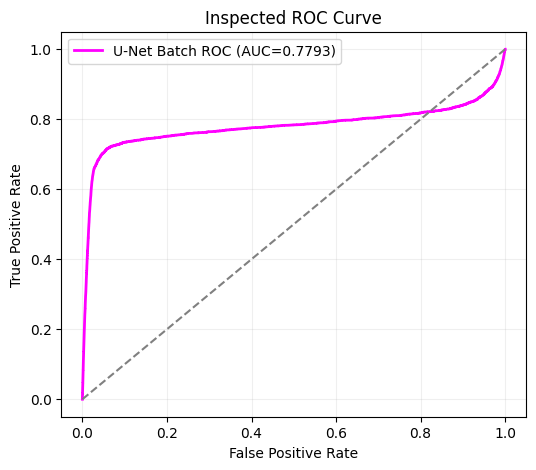

In [ ]:
import numpy as np
import torch
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Gather prediction values across the 10 images
all_y_true = []
all_y_scores = []

model.eval()
images_counted = 0
max_images = 10

with torch.no_grad():
    for batch_images, batch_masks in val_loader:
        if images_counted >= max_images:
            break

        batch_images_gpu = batch_images.to(device)
        outputs = model(batch_images_gpu)
        probs = torch.sigmoid(outputs).cpu().numpy()
        masks_np = batch_masks.numpy()

        for i in range(len(batch_images)):
            if images_counted >= max_images:
                break
            all_y_true.append(masks_np[i].flatten())
            all_y_scores.append(probs[i].flatten())
            images_counted += 1

# 2. Flatten into comprehensive global arrays
y_true_global = np.concatenate(all_y_true)
y_scores_global = np.concatenate(all_y_scores)

# 3. Compute arrays of FPR, TPR, and the corresponding thresholds
fpr, tpr, thresholds = roc_curve(y_true_global, y_scores_global)
auc_val = roc_auc_score(y_true_global, y_scores_global)

# 4. Print out a clean, sampled table of the coordinates
print("=" * 60)
print(f"       ROC CURVE DATA POINTS (10-Image Subset | AUC: {auc_val:.4f})")
print("=" * 60)
print(f"{'Classification Threshold':<25} | {'FPR (1 - Spec)':<15} | {'TPR (Sens)':<15}")
print("-" * 60)

# Sample the massive arrays at clean classification cutoffs to inspect numerical behavior
target_thresholds = [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]

for target in target_thresholds:
    # Find the index of the closest calculated threshold matching our target
    idx = np.argmin(np.abs(thresholds - target))
    print(f"{thresholds[idx]:<25.4f} | {fpr[idx]:<15.5f} | {tpr[idx]:<15.5f}")

print("=" * 60)

# 5. Quick verification plot
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='magenta', lw=2, label=f'U-Net Batch ROC (AUC={auc_val:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Inspected ROC Curve')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()